# История WB и административная структура поселений

## Полученный результат
Найдены и проверены семь реальных архивных каталогов WB2022–2024, официальные
выпуски ОКТМО2015/2020/2021/2022/2026 и региональные ряды физических магазинов.
Теперь можно исследовать изменения наблюдаемого каталожного следа на общей оси
поселений. Сопоставимая причинная оценка влияния на магазины или население пока
не построена. История Ozon2019–2025 в проверенных источниках не получена.

Смена типов точек и заполнения полей исключает механическое сравнение одного
фильтра8/34 за все годы. Новое правило привязки отличается от прежнего моста WB:
нынешние счётчики этого ноутбука нельзя смешивать с прежними7991НП.

## Метод и ограничения
Все адреса связываются с одной принятой осью зачтённых НП2021 по одинаковому
правилу: точное нормализованное имя в первых четырёх компонентах адреса,
разделённых запятой, плюс координаты и единственность кандидата в1/5/10км.
Снимаются известные префиксы типа и уточнения в скобках. Исторические связи
не ограничиваются выжившими объектами2026; неизвестное сохраняется.
Это проверка имени и близости к опорной точке, не принадлежности официальной
границе. Непривязанные объекты не объявляются отсутствующей услугой.

Административные центры определены независимо от маркетплейсов по ОКТМО.
Муниципальное окружение не является измеренным торговым ареалом. Один центр
нескольких МО в национальном анализе учитывается один раз. Неполная связка
с историческими кодами и неустановленная неизменность границ раскрыты отдельно.

Даты архивов — наблюдения каталога, не открытия. Разность следов может содержать
рост инфраструктуры, изменение состава каталога, качества адресов и привязок.
Ни один приведённый счётчик не является оценкой причинного эффекта.

## Воспроизведение
Рабочая папка: history_stage_20261024. Требуются локальные parquet предыдущего
этапа, скачанные архивы и полученный слой ОКТМО. Запуск использует Python
с pandas/numpy/pyarrow/scipy/matplotlib/nbformat/nbclient/ipykernel.
В текущей среде pyarrow доступен через
PYTHONPATH=/tmp/ecommerce_audit_20261024_pyarrow.
Скрипты загрузки и их манифесты находятся в network/, centres/ и retail/.

In [1]:
from pathlib import Path
import contextlib, io, json, runpy
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
assert (ROOT/'network/wb_history_normalized.parquet').exists()
for script in ['analyze_admin_network.py','link_history_symmetrically.py',
               'authors/inspect_author_sources.py']:
    with contextlib.redirect_stdout(io.StringIO()):
        runpy.run_path(str(ROOT/script),run_name='__main__')
    print('Выполнен:',script)
plt.rcParams.update({'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.axisbelow':True})


Выполнен: analyze_admin_network.py


Выполнен: link_history_symmetrically.py
Выполнен: authors/inspect_author_sources.py


## Архивные срезы и полнота привязки
Объекты all-catalogue включают все исходные типы. Их смысл и состав меняются;
ниже не представлен однородный ряд клиентских ПВЗ. Большее окно поиска может
создать неоднозначность одноимённых кандидатов и уменьшить число принятых связей.

In [2]:
inventory=pd.read_csv(ROOT/'wb_history_linkage_inventory.csv')
display(inventory[inventory.radius_km.eq(5)].drop(columns='status_counts'))
flags=pd.read_csv(ROOT/'network/historical_raw_flag_profile.csv')
display(flags)


,archive_date,radius_km,ru_catalogue_objects,linked_objects,unresolved_or_ambiguous
8,2022-09-29,5,22792,12332,10460
9,2022-11-18,5,23944,13100,10844
10,2023-01-01,5,24701,13670,11031
11,2023-05-30,5,26713,15282,11431
12,2023-07-06,5,26616,15326,11290
13,2023-08-15,5,26744,15313,11431
14,2024-03-11,5,35105,21020,14085
15,2026-10-21,5,91043,63678,27365


,archive_date,ru_objects_n,dtype0_isWbtrue_n,dtype0_isWbtrue_pickupType3or4_n,raw_profile_share_ru,profile_is_semantic_client_classification
0,2022-09-29,22792,22755,22128,0.970867,False
1,2022-11-18,23944,23907,22978,0.959656,False
2,2023-01-01,24701,24664,23706,0.959718,False
3,2023-05-30,26713,26680,25665,0.960768,False
4,2023-07-06,26616,26616,25649,0.963668,False
5,2023-08-15,26744,26662,25750,0.962833,False
6,2024-03-11,35105,34332,34313,0.977439,False


## Изменения наблюдаемого следа
Примерочные показываются как отдельный профиль заполнения исходного поля.
Их рост не равен росту ПВЗ:3804одинаковыхID, почти не изменивших координаты,
перешли от пропуска2024 к положительному значению2026. Старые флаги dtype/isWb/
pickupType вообще отсутствуют во всех91043записях исходного среза2026.

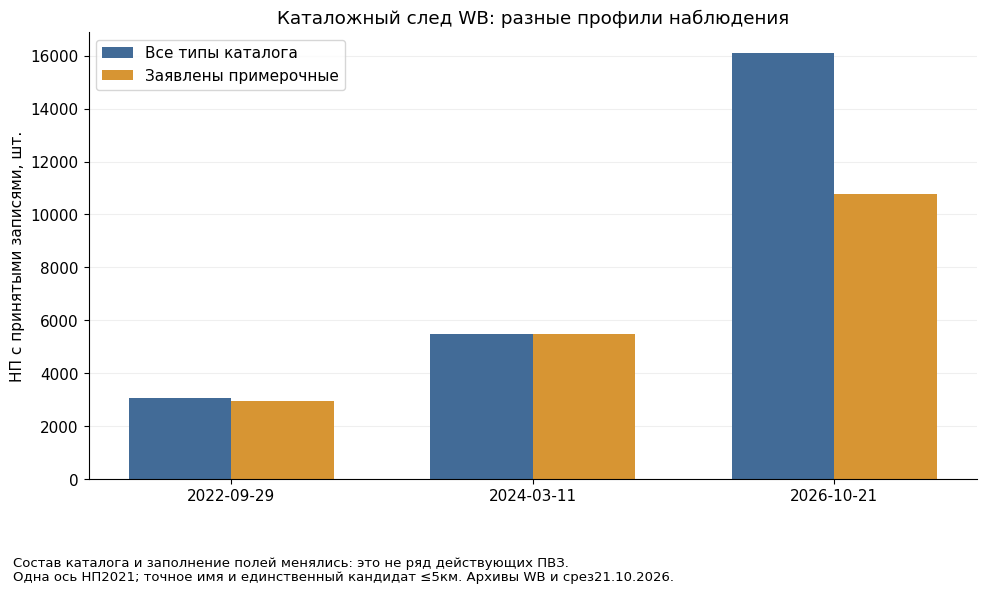

In [3]:
f=pd.read_csv(ROOT/'wb_history_admin_footprints.csv')
plot=f[(f.radius_km==5)&(f.context_vintage==20211103)&
       f.archive_date.isin(['2022-09-29','2024-03-11','2026-10-21'])]
dates=['2022-09-29','2024-03-11','2026-10-21']
fig,ax=plt.subplots(figsize=(10,6))
for j,(profile,label,color) in enumerate([
    ('all_catalogue','Все типы каталога','#426b97'),
    ('fitting_positive_observed','Заявлены примерочные','#d79533')]):
    z=plot[plot.profile.eq(profile)].set_index('archive_date').loc[dates]
    ax.bar([x+(j-.5)*.34 for x in range(3)],z.positive_nodes,width=.34,
           label=label,color=color)
ax.set_xticks(range(3),dates)
ax.set_ylabel('НП с принятыми записями, шт.')
ax.set_title('Каталожный след WB: разные профили наблюдения')
ax.grid(axis='y',alpha=.2)
ax.legend()
fig.tight_layout()
fig.subplots_adjust(bottom=.19)
fig.text(.02,.02,'Состав каталога и заполнение полей менялись: это не ряд действующих ПВЗ.\n'
         'Одна ось НП2021; точное имя и единственный кандидат ≤5км. Архивы WB и срез21.10.2026.',
         fontsize=9.5)
fig.savefig(ROOT/'catalogue_profiles.png',dpi=150)
plt.show()


## Асимметричная проверка добавочных положительных записей
Сравниваем выбранные нынешние типы8/34 с ЛЮБОЙ старой записью каталога,
не перенося текущий тип на исторический объект. Это консервативная проверка
относительно состава старого каталога. Она сохраняет риски его неполноты,
изменившегося адреса и ошибки связи, поэтому не измеряет реальные открытия.

In [4]:
changes=pd.read_csv(ROOT/'wb_catalogue_footprint_changes.csv')
display(changes[changes.older_date.eq('2024-03-11')][
    ['radius_km','older_catalogue_nodes','current_focus_nodes',
     'current_focus_nodes_without_old_any_catalogue_record',
     'focus_latter_documented_centres2021',
     'focus_latter_other_known_members2021']])


,radius_km,older_catalogue_nodes,current_focus_nodes,current_focus_nodes_without_old_any_catalogue_record,focus_latter_documented_centres2021,focus_latter_other_known_members2021
6,1,4906,7398,2660,178,2332
13,5,5491,7933,2616,66,2399
20,10,5454,7888,2608,68,2390


## Центры и наблюдаемое муниципальное окружение
Этот раздел использует исходный текущий профиль WB и экспериментальный Ozon
предыдущего этапа, а не новый исторический алгоритм. В каждой таблице собственный
явный знаменатель. Сосуществование записей в центре и окружении не доказывает
ни комплементарность торговли, ни утрату покупательских потоков центром.

,vintage,ozon_link_radius_km,role,settlements,population2021,positive_settlements,positive_population2021,positive_settlements_pct,positive_population2021_pct
12,20211103,5,documented_centre,2056,87969772.0,1991,87471597.0,96.84,99.43
13,20211103,5,other_accepted_member,133971,33763603.0,15314,22435340.0,11.43,66.45
14,20211103,5,unknown_context,8124,3983921.0,1006,3122695.0,12.38,78.38


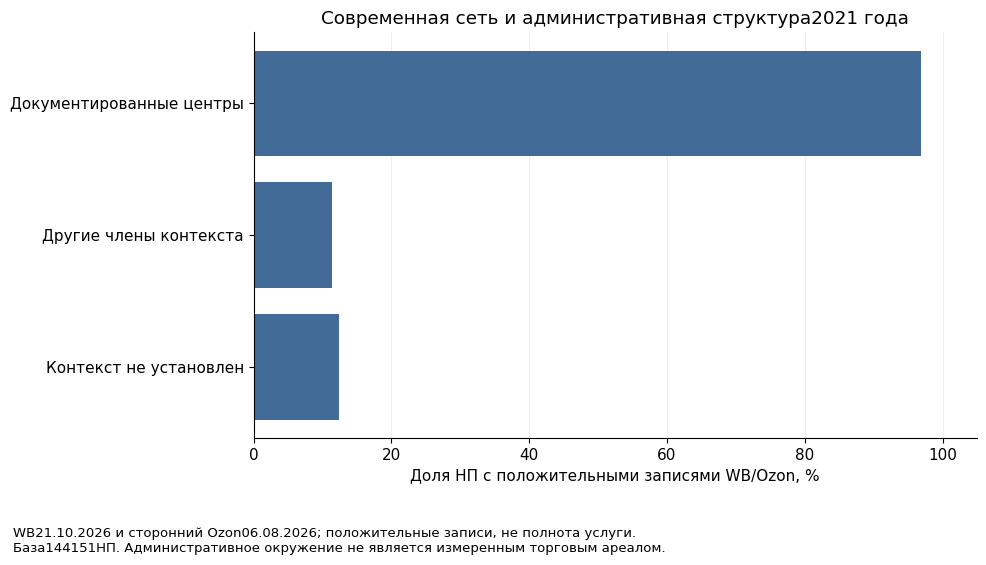

,vintage,ozon_link_radius_km,category,centres,observed_other_members,observed_inhabited_other_members
20,20211103,5,no_inhabited_other_members_observed,139,1,0
21,20211103,5,no_positive_records_in_observed_context,30,464,413
22,20211103,5,positive_centre_and_other_members,1681,122548,105179
23,20211103,5,positive_centre_no_positive_other_members,172,8122,5997
24,20211103,5,positive_other_members_no_positive_centre,34,2836,2494


In [5]:
r=pd.read_csv(ROOT/'admin_roles_network.csv')
r=r[(r.vintage==20211103)&(r.ozon_link_radius_km==5)]
display(r.round(2))
z=r.set_index('role').loc[['documented_centre','other_accepted_member','unknown_context']]
fig,ax=plt.subplots(figsize=(10,5.7))
ax.barh(['Документированные центры','Другие члены контекста','Контекст не установлен'],
        z.positive_settlements_pct,color='#426b97')
ax.set_xlim(0,105)
ax.set_xlabel('Доля НП с положительными записями WB/Ozon, %')
ax.set_title('Современная сеть и административная структура2021 года')
ax.grid(axis='x',alpha=.2)
ax.invert_yaxis()
fig.tight_layout()
fig.subplots_adjust(bottom=.22)
fig.text(.02,.02,'WB21.10.2026 и сторонний Ozon06.08.2026; положительные записи, не полнота услуги.\n'
         'База144151НП. Административное окружение не является измеренным торговым ареалом.',fontsize=9.5)
fig.savefig(ROOT/'admin_network_presence.png',dpi=150)
plt.show()
display(pd.read_csv(ROOT/'admin_context_categories.csv').query(
    'vintage==20211103 and ozon_link_radius_km==5'))


## Физические магазины: новый независимый исход
Росстат дал региональные ряды, включая вложенные и федеральные итоги:
4200годовых и18176квартальных наблюдений. Их нельзя складывать без выбора
географического уровня. Они не дают числа магазинов каждого поселения.
Смена формы2022, категорий2024/2025 и уточнения респондентов требуют аудита
конкретного ряда. Пример ниже — запас непродовольственных магазинов одного
региона; разность запаса не равна числу закрытий и не приписывается ПВЗ.

In [6]:
retail=pd.read_csv(ROOT/'retail/rosstat_physical_retail_quarterly_2022_2024_long.csv')
z=retail[retail.territory_raw.str.contains('Нижегородская',na=False)&
         retail.category_raw.str.contains('непродоволь',case=False,na=False)&
         retail.observation_date.str.endswith('12-31')]
display(z[['territory_raw','observation_date','category_raw','value','source_sheet','source_cell']])


,territory_raw,observation_date,category_raw,value,source_sheet,source_cell
1843,Нижегородская область,2022-12-31,Специализированные непродовольственные магазины,5317.0,2022,U64
7859,Нижегородская область,2023-12-31,Специализированные непродовольственные магазины,5383.0,2023,U64
13915,Нижегородская область,2024-12-31,Специализированные непродовольственные магазины,5279.0,2024,U66


## Вывод и следующий исследовательский рубеж
Появилась реальная временная основа WB и независимая национальная классификация
административных центров. Каталожные записи распространяются вне этих центров;
сами центры при этом почти повсеместно имеют положительные записи сети.
Это совместимо с рассредоточением инфраструктуры получения товаров, но пока
не устанавливает ослабление торговых функций центра или причинный эффект.

Для следующего шага нужны сопоставимые профили точек между форматами каталога,
история Ozon, физические магазины на уровне НП/МО и проверка изменений границ.
Покупательские потоки в обязательные измерения не возвращаются.
Подробные источники, проверки и ограничения: HISTORY_RESULTS.txt и подпапки.
Предыдущие расчёты и исходные таблицы сохранены.